# Studi Komparatif Model Generatif (Fashion-MNIST)

## 1. Setup dan Seed

In [1]:
import os
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, models
from sklearn.model_selection import StratifiedShuffleSplit

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

SEED = 42
BATCH_SIZE = 128
FORCE_RERUN = False

DATA_ROOT = "data"
RESULTS_DIR = "results"
FIGS_DIR = os.path.join(RESULTS_DIR, "figs")
WEIGHTS_DIR = os.path.join(RESULTS_DIR, "weights")
SPLITS_PATH = os.path.join(RESULTS_DIR, "splits.json")
RUNS_PATH = os.path.join(RESULTS_DIR, "runs.csv")
METRICS_PATH = os.path.join(RESULTS_DIR, "metrics.json")

for folder in (DATA_ROOT, FIGS_DIR, WEIGHTS_DIR):
    os.makedirs(folder, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

set_seed(SEED)
print(f"Working dir: {os.getcwd()}")
print(f"PyTorch: {torch.__version__} | Device: {device}")


Working dir: /home/cele/kuliah/semester-5/deep-learning/tugas-ae-gan
PyTorch: 2.5.1+cu121 | Device: cuda


## 2. Dataset dan Split 80/10/10


Total: 70000 | Train: 56000 | Val: 7000 | Test: 7000
Pixel range: 0.0 to 1.0


,train,val,test
T-shirt/top,5600,700,700
Trouser,5600,700,700
Pullover,5600,700,700
Dress,5600,700,700
Coat,5600,700,700
Sandal,5600,700,700
Shirt,5600,700,700
Sneaker,5600,700,700
Bag,5600,700,700
Ankle boot,5600,700,700


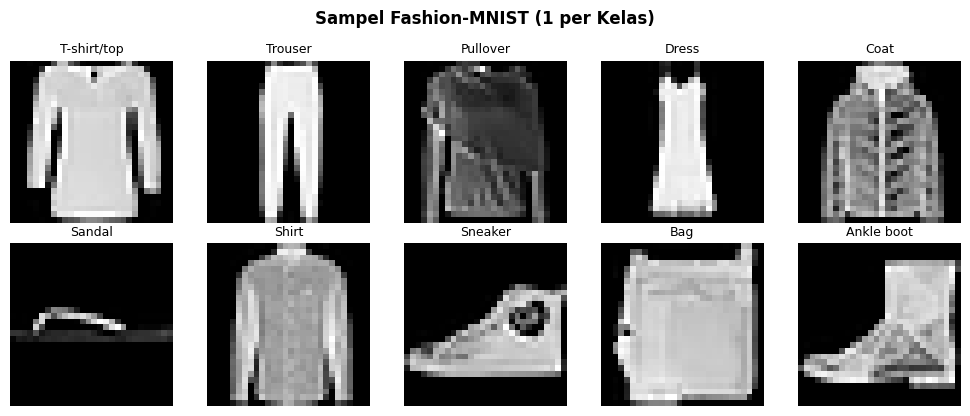

In [2]:
raw_train = datasets.FashionMNIST(root=DATA_ROOT, train=True, download=True)
raw_test = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True)

CLASS_NAMES = list(raw_train.classes)
all_images_u8 = torch.cat([raw_train.data, raw_test.data], dim=0)
all_targets = torch.cat([raw_train.targets, raw_test.targets], dim=0)
all_images = all_images_u8.float().unsqueeze(1) / 255.0

if os.path.exists(SPLITS_PATH):
    with open(SPLITS_PATH) as f:
        splits = json.load(f)
else:
    labels_np = all_targets.numpy()
    indices_np = np.arange(len(labels_np))
    train_idx, rest_idx = next(
        StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(indices_np, labels_np)
    )
    rest_labels = labels_np[rest_idx]
    val_pos, test_pos = next(
        StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED).split(rest_idx, rest_labels)
    )
    val_idx, test_idx = rest_idx[val_pos], rest_idx[test_pos]

    assert not (set(train_idx) & set(val_idx))
    assert not (set(train_idx) & set(test_idx))
    assert not (set(val_idx) & set(test_idx))

    splits = {
        "classes": CLASS_NAMES,
        "train_indices": [int(i) for i in train_idx],
        "val_indices": [int(i) for i in val_idx],
        "test_indices": [int(i) for i in test_idx],
    }
    with open(SPLITS_PATH, "w") as f:
        json.dump(splits, f)

train_ds = TensorDataset(all_images[splits["train_indices"]], all_targets[splits["train_indices"]])
val_ds = TensorDataset(all_images[splits["val_indices"]], all_targets[splits["val_indices"]])
test_ds = TensorDataset(all_images[splits["test_indices"]], all_targets[splits["test_indices"]])

loader_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    generator=loader_gen, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=torch.cuda.is_available())

print(f"Total: {len(all_images)} | Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
print(f"Pixel range: {all_images.min().item():.1f} to {all_images.max().item():.1f}")

targets_np = all_targets.numpy()
dist_df = pd.DataFrame(
    {name: np.bincount(targets_np[splits[f"{name}_indices"]], minlength=len(CLASS_NAMES)) for name in ("train", "val", "test")},
    index=CLASS_NAMES,
)
display(dist_df)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for cls_idx, ax in enumerate(axes.flat):
    sample_pos = (all_targets[splits["train_indices"]] == cls_idx).nonzero(as_tuple=True)[0][0].item()
    ax.imshow(train_ds[sample_pos][0].squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[cls_idx], fontsize=9)
    ax.axis("off")
plt.suptitle("Sampel Fashion-MNIST (1 per Kelas)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "fashion_mnist_samples.png"), dpi=300, bbox_inches="tight")
plt.show()


## 3. Helper Evaluasi dan Visualisasi


In [3]:
def gaussian_window(window_size=11, sigma=1.5, dev="cpu"):
    coords = torch.arange(window_size, dtype=torch.float32, device=dev) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return torch.outer(g, g).unsqueeze(0).unsqueeze(0)

def compute_ssim_batch(x, y, window_size=11, sigma=1.5):
    window = gaussian_window(window_size, sigma, x.device)
    mu1 = F.conv2d(x, window)
    mu2 = F.conv2d(y, window)
    mu1_sq = mu1.pow(2)
    mu2_sq = mu2.pow(2)
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(x * x, window) - mu1_sq
    sigma2_sq = F.conv2d(y * y, window) - mu2_sq
    sigma12 = F.conv2d(x * y, window) - mu1_mu2

    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.mean(dim=(1, 2, 3))

@torch.no_grad()
def evaluate_reconstruction(recon_fn, loader):
    mse_list, psnr_list, ssim_list = [], [], []
    for x, _ in loader:
        x = x.to(device)
        x_hat = recon_fn(x).clamp(0.0, 1.0)
        mse = ((x - x_hat) ** 2).mean(dim=(1, 2, 3))
        psnr = 10.0 * torch.log10(1.0 / mse.clamp(min=1e-10))
        ssim = compute_ssim_batch(x, x_hat)
        mse_list.append(mse.cpu())
        psnr_list.append(psnr.cpu())
        ssim_list.append(ssim.cpu())
    return (
        float(torch.cat(mse_list).mean()),
        float(torch.cat(psnr_list).mean()),
        float(torch.cat(ssim_list).mean()),
    )

@torch.no_grad()
def measure_latency_ms(sample_fn, warmup=5, repeats=100):
    for _ in range(warmup):
        _ = sample_fn()
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        _ = sample_fn()
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed_ms = (time.perf_counter() - start) * 1000.0 / repeats
    return round(elapsed_ms, 3)

def load_inception_extractor():
    model = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
    model.fc = nn.Identity()
    return model.to(device).eval()

@torch.no_grad()
def extract_inception_features(images_01, inception, batch_size=128):
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    feats = []
    for i in range(0, len(images_01), batch_size):
        batch = images_01[i : i + batch_size].to(device).clamp(0.0, 1.0)
        batch = batch.repeat(1, 3, 1, 1)
        batch = F.interpolate(batch, size=(299, 299), mode="bilinear", align_corners=False)
        batch = (batch - mean) / std
        feats.append(inception(batch).cpu().numpy())
    return np.concatenate(feats, axis=0).astype(np.float64)

def compute_fid_from_features(real_feats, fake_feats):
    mu1, sigma1 = real_feats.mean(axis=0), np.cov(real_feats, rowvar=False)
    mu2, sigma2 = fake_feats.mean(axis=0), np.cov(fake_feats, rowvar=False)
    diff = mu1 - mu2
    covmean = linalg.sqrtm(sigma1 @ sigma2)
    if not np.isfinite(covmean).all():
        eps = 1e-6 * np.eye(sigma1.shape[0])
        covmean = linalg.sqrtm((sigma1 + eps) @ (sigma2 + eps))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2.0 * np.trace(covmean))

def save_grid(images_01, nrow, ncol, title, path=None, show=True):
    imgs = images_01[: nrow * ncol].detach().cpu().squeeze(1).numpy()
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 1.6, nrow * 1.6), squeeze=False)
    for ax, img in zip(axes.flat, imgs):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    if title:
        fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()

FID_N_SAMPLES = 5000
inception_model = load_inception_extractor()
real_fid_images = all_images[splits["test_indices"]][:FID_N_SAMPLES]
real_fid_features = extract_inception_features(real_fid_images, inception_model)

id_mse, id_psnr, id_ssim = evaluate_reconstruction(nn.Identity(), test_loader)
print(f"Identity sanity -> MSE: {id_mse:.6f} | PSNR: {id_psnr:.2f} dB | SSIM: {id_ssim:.6f}")

train_fid_images = all_images[splits["train_indices"]][:FID_N_SAMPLES]
train_fid_features = extract_inception_features(train_fid_images, inception_model)
fid_floor = compute_fid_from_features(real_fid_features, train_fid_features)
print(f"Cached real FID features: {real_fid_features.shape} | FID floor (test vs train): {fid_floor:.2f}")


Identity sanity -> MSE: 0.000000 | PSNR: 100.00 dB | SSIM: 1.000000


Cached real FID features: (5000, 2048) | FID floor (test vs train): 5.48


## 4. MLP Classifier Pendamping

In [4]:
class MLPClassifier(nn.Module):
    def __init__(self, in_dim=784, hidden_dim=256, latent_dim=64, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, latent_dim)
        self.fc3 = nn.Linear(latent_dim, num_classes)

    def encode(self, x):
        h1 = F.relu(self.fc1(x.flatten(1)))
        return F.relu(self.fc2(h1))

    def forward(self, x):
        return self.fc3(self.encode(x))

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)
    return total_loss / count, correct / count

print(MLPClassifier())
trainable, total = count_parameters(MLPClassifier())
print(f"Params trainable: {trainable:,} | total: {total:,}")


MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)
Params trainable: 218,058 | total: 218,058


### 4.1 Training MLP Classifier


In [5]:
MLP_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "mlp_classifier.pt")
MLP_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_mlp.csv")
MLP_EPOCHS = 20
MLP_LR = 1e-3

set_seed(SEED)
loader_gen.manual_seed(SEED)
mlp = MLPClassifier().to(device)

if os.path.exists(MLP_WEIGHTS_PATH) and os.path.exists(MLP_HISTORY_PATH) and not FORCE_RERUN:
    mlp.load_state_dict(torch.load(MLP_WEIGHTS_PATH, map_location=device, weights_only=True))
    mlp_history = pd.read_csv(MLP_HISTORY_PATH)
    print("Cache dimuat: mlp_classifier.pt")
else:
    optimizer = torch.optim.Adam(mlp.parameters(), lr=MLP_LR)
    best_acc, best_state, rows = 0.0, None, []
    for epoch in range(1, MLP_EPOCHS + 1):
        mlp.train()
        start = time.perf_counter()
        running_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(mlp(x), y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
        epoch_time = time.perf_counter() - start
        val_loss, val_acc = evaluate_classifier(mlp, val_loader)
        rows.append({
            "epoch": epoch,
            "train_loss": running_loss / len(train_ds),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch_time_s": epoch_time,
        })
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in mlp.state_dict().items()}
        print(f"Epoch {epoch:02d}/{MLP_EPOCHS} | train {rows[-1]['train_loss']:.4f} | val {val_loss:.4f} | acc {val_acc * 100:.2f}% | {epoch_time:.2f}s")
    mlp.load_state_dict(best_state)
    torch.save(mlp.state_dict(), MLP_WEIGHTS_PATH)
    mlp_history = pd.DataFrame(rows)
    mlp_history.to_csv(MLP_HISTORY_PATH, index=False)

display(mlp_history.tail())


Cache dimuat: mlp_classifier.pt


,epoch,train_loss,val_loss,val_acc,epoch_time_s
15,16,0.206483,0.315650,0.889571,1.060741
16,17,0.199529,0.327798,0.882000,1.035472
17,18,0.194230,0.334115,0.885429,1.207368
18,19,0.185800,0.344214,0.884857,1.140272
19,20,0.179623,0.361101,0.880286,1.142810


### 4.2 Evaluasi Test MLP Classifier


In [6]:
mlp_test_loss, mlp_test_acc = evaluate_classifier(mlp, test_loader)
print(f"Test loss: {mlp_test_loss:.4f} | Test acc: {mlp_test_acc * 100:.2f}%")
assert mlp_test_acc >= 0.88

with torch.no_grad():
    z_test = torch.cat([mlp.encode(x.to(device)).cpu() for x, _ in test_loader])

print(f"W1 {tuple(mlp.fc1.weight.shape)} | W2 {tuple(mlp.fc2.weight.shape)} | W3 {tuple(mlp.fc3.weight.shape)}")
print(f"z_MLP: {tuple(z_test.shape)} | fraksi nol: {(z_test == 0).float().mean().item():.3f}")
print(f"Rata-rata waktu per epoch: {mlp_history['epoch_time_s'].mean():.2f}s")


Test loss: 0.3072 | Test acc: 89.80%
W1 (256, 784) | W2 (64, 256) | W3 (10, 64)
z_MLP: (7000, 64) | fraksi nol: 0.502
Rata-rata waktu per epoch: 1.08s


## 5. Vanilla Autoencoder


In [7]:
class VanillaAE(nn.Module):
    def __init__(self, in_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, in_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x.flatten(1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

@torch.no_grad()
def evaluate_mse(model, loader):
    model.eval()
    total, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        total += F.mse_loss(model(x), x, reduction="sum").item()
        count += x.numel()
    return total / count

print(VanillaAE())
trainable, total = count_parameters(VanillaAE())
print(f"Params trainable: {trainable:,} | total: {total:,}")


VanillaAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Params trainable: 435,536 | total: 435,536


### 5.1 Training Vanilla Autoencoder


In [8]:
AE_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "vanilla_ae.pt")
AE_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_vanilla_ae.csv")
AE_EPOCHS = 30
AE_LR = 1e-3

set_seed(SEED)
loader_gen.manual_seed(SEED)
ae = VanillaAE().to(device)

if os.path.exists(AE_WEIGHTS_PATH) and os.path.exists(AE_HISTORY_PATH) and not FORCE_RERUN:
    ae.load_state_dict(torch.load(AE_WEIGHTS_PATH, map_location=device, weights_only=True))
    ae_history = pd.read_csv(AE_HISTORY_PATH)
    print("Cache dimuat: vanilla_ae.pt")
else:
    optimizer = torch.optim.Adam(ae.parameters(), lr=AE_LR)
    best_loss, best_state, rows = float("inf"), None, []
    for epoch in range(1, AE_EPOCHS + 1):
        ae.train()
        start = time.perf_counter()
        running_loss = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            loss = F.mse_loss(ae(x), x)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
        epoch_time = time.perf_counter() - start
        train_loss = running_loss / len(train_ds)
        val_loss = evaluate_mse(ae, val_loader)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "epoch_time_s": epoch_time})
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in ae.state_dict().items()}
        print(f"Epoch {epoch:02d}/{AE_EPOCHS} | train {train_loss:.5f} | val {val_loss:.5f} | {epoch_time:.2f}s")
    ae.load_state_dict(best_state)
    torch.save(ae.state_dict(), AE_WEIGHTS_PATH)
    ae_history = pd.DataFrame(rows)
    ae_history.to_csv(AE_HISTORY_PATH, index=False)

display(ae_history.tail())


Cache dimuat: vanilla_ae.pt


,epoch,train_loss,val_loss,epoch_time_s
25,26,0.006412,0.006658,1.031343
26,27,0.006382,0.006607,0.996118
27,28,0.006332,0.006585,0.968285
28,29,0.006288,0.006543,0.974802
29,30,0.006251,0.006490,1.011970


### 5.2 Evaluasi Test Vanilla Autoencoder


{'model': 'Vanilla AE', 'latent_dim': 64, 'train_time_per_epoch_s': 1.247, 'latency_ms': 0.117, 'mse': 0.006387215573340654, 'psnr': 23.069475173950195, 'ssim': 0.7919896245002747, 'fid': None}


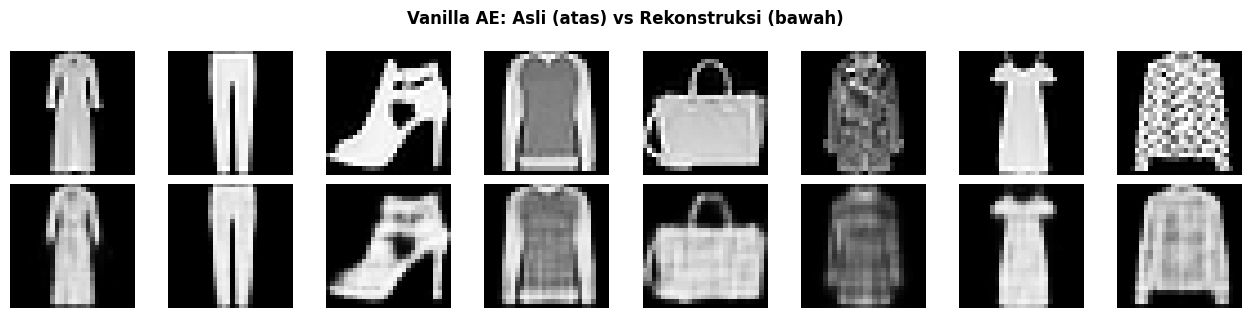

In [9]:
ae.eval()
ae_mse, ae_psnr, ae_ssim = evaluate_reconstruction(ae, test_loader)

x64 = test_ds.tensors[0][:64].to(device)
ae_latency = measure_latency_ms(lambda: ae(x64), repeats=100)

ae_result = {
    "model": "Vanilla AE",
    "latent_dim": 64,
    "train_time_per_epoch_s": round(ae_history["epoch_time_s"].mean(), 3),
    "latency_ms": ae_latency,
    "mse": ae_mse,
    "psnr": ae_psnr,
    "ssim": ae_ssim,
    "fid": None,
}
print(ae_result)

x8 = test_ds.tensors[0][:8].to(device)
with torch.no_grad():
    x8_hat = ae(x8)
save_grid(torch.cat([x8, x8_hat]), 2, 8, "Vanilla AE: Asli (atas) vs Rekonstruksi (bawah)", os.path.join(FIGS_DIR, "vanilla_ae_preview.png"))


## 6. Sparse Autoencoder


In [10]:
class SparseAE(nn.Module):
    def __init__(self, in_dim=784, hidden_dim=512, latent_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, in_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x.flatten(1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

@torch.no_grad()
def evaluate_sparse(model, loader, lam):
    model.eval()
    recon_sum, penalty_sum, count = 0.0, 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        z = model.encode(x)
        recon_sum += F.mse_loss(model.decode(z), x, reduction="sum").item()
        penalty_sum += z.abs().sum().item()
        count += x.size(0)
    recon = recon_sum / (count * 784)
    penalty = penalty_sum / count
    return recon, penalty, recon + lam * penalty

print(SparseAE())
trainable, total = count_parameters(SparseAE())
print(f"Params trainable: {trainable:,} | total: {total:,}")


SparseAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=256, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Params trainable: 1,067,024 | total: 1,067,024


### 6.1 Training Sparse Autoencoder


In [11]:
SPARSE_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "sparse_ae.pt")
SPARSE_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_sparse_ae.csv")
SPARSE_EPOCHS = 30
SPARSE_LR = 1e-3
SPARSE_LAMBDA = 1e-4

set_seed(SEED)
loader_gen.manual_seed(SEED)
sparse_ae = SparseAE().to(device)

if os.path.exists(SPARSE_WEIGHTS_PATH) and os.path.exists(SPARSE_HISTORY_PATH) and not FORCE_RERUN:
    sparse_ae.load_state_dict(torch.load(SPARSE_WEIGHTS_PATH, map_location=device, weights_only=True))
    sparse_history = pd.read_csv(SPARSE_HISTORY_PATH)
    print("Cache dimuat: sparse_ae.pt")
else:
    optimizer = torch.optim.Adam(sparse_ae.parameters(), lr=SPARSE_LR)
    best_loss, best_state, rows = float("inf"), None, []
    for epoch in range(1, SPARSE_EPOCHS + 1):
        sparse_ae.train()
        start = time.perf_counter()
        running_loss, running_recon = 0.0, 0.0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            z = sparse_ae.encode(x)
            recon = F.mse_loss(sparse_ae.decode(z), x)
            loss = recon + SPARSE_LAMBDA * z.abs().sum(dim=1).mean()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
            running_recon += recon.item() * x.size(0)
        epoch_time = time.perf_counter() - start
        val_recon, _, val_loss = evaluate_sparse(sparse_ae, val_loader, SPARSE_LAMBDA)
        rows.append({
            "epoch": epoch,
            "train_loss": running_loss / len(train_ds),
            "train_recon": running_recon / len(train_ds),
            "val_loss": val_loss,
            "val_recon": val_recon,
            "epoch_time_s": epoch_time,
        })
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in sparse_ae.state_dict().items()}
        print(f"Epoch {epoch:02d}/{SPARSE_EPOCHS} | train {rows[-1]['train_loss']:.5f} | val {val_loss:.5f} | val recon {val_recon:.5f} | {epoch_time:.2f}s")
    sparse_ae.load_state_dict(best_state)
    torch.save(sparse_ae.state_dict(), SPARSE_WEIGHTS_PATH)
    sparse_history = pd.DataFrame(rows)
    sparse_history.to_csv(SPARSE_HISTORY_PATH, index=False)

display(sparse_history.tail())


Cache dimuat: sparse_ae.pt


,epoch,train_loss,train_recon,val_loss,val_recon,epoch_time_s
25,26,0.007797,0.006940,0.008113,0.007246,1.321049
26,27,0.007724,0.006878,0.008016,0.007195,1.294292
27,28,0.007647,0.006809,0.007903,0.007078,1.243685
28,29,0.007582,0.006755,0.007905,0.007064,1.265411
29,30,0.007534,0.006718,0.007840,0.007033,1.372927


### 6.2 Evaluasi Test Sparse Autoencoder


Sparsity: 78.28% nol | Unit mati: 179/256
{'model': 'Sparse AE', 'latent_dim': 256, 'train_time_per_epoch_s': 1.346, 'latency_ms': 0.133, 'mse': 0.006936703808605671, 'psnr': 22.66019630432129, 'ssim': 0.7777045965194702, 'fid': None, 'sparsity': 0.7828208804130554, 'lambda': 0.0001}


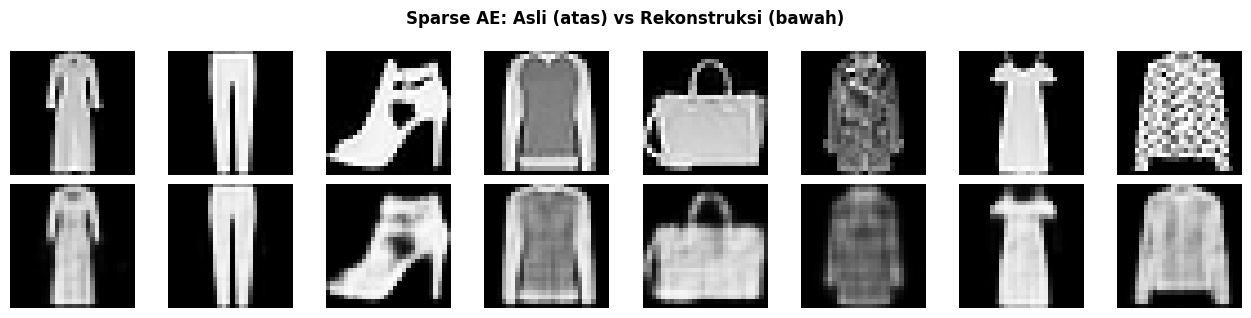

In [12]:
sparse_ae.eval()
sparse_mse, sparse_psnr, sparse_ssim = evaluate_reconstruction(sparse_ae, test_loader)

with torch.no_grad():
    z_sparse = torch.cat([sparse_ae.encode(x.to(device)).cpu() for x, _ in test_loader])
sparsity = (z_sparse == 0).float().mean().item()
dead_units = int((z_sparse.max(dim=0).values == 0).sum())
print(f"Sparsity: {sparsity * 100:.2f}% nol | Unit mati: {dead_units}/{z_sparse.size(1)}")
assert sparsity < 0.99

sparse_latency = measure_latency_ms(lambda: sparse_ae(x64), repeats=100)

sparse_result = {
    "model": "Sparse AE",
    "latent_dim": 256,
    "train_time_per_epoch_s": round(sparse_history["epoch_time_s"].mean(), 3),
    "latency_ms": sparse_latency,
    "mse": sparse_mse,
    "psnr": sparse_psnr,
    "ssim": sparse_ssim,
    "fid": None,
    "sparsity": sparsity,
    "lambda": SPARSE_LAMBDA,
}
print(sparse_result)

with torch.no_grad():
    x8_sparse = sparse_ae(x8)
save_grid(torch.cat([x8, x8_sparse]), 2, 8, "Sparse AE: Asli (atas) vs Rekonstruksi (bawah)", os.path.join(FIGS_DIR, "sparse_ae_preview.png"))


## 7. Variational Autoencoder (VAE)


In [13]:
class VAE(nn.Module):
    def __init__(self, in_dim=784, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.fc3 = nn.Linear(latent_dim, hidden_dim)
        self.fc4 = nn.Linear(hidden_dim, in_dim)

    def encode(self, x):
        h = F.relu(self.fc1(x.flatten(1)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)

    def decode(self, z):
        h = F.relu(self.fc3(z))
        return torch.sigmoid(self.fc4(h)).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

def vae_loss(x_hat, x, mu, logvar):
    batch = x.size(0)
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / batch
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch
    return recon + kl, recon, kl

@torch.no_grad()
def evaluate_vae(model, loader):
    model.eval()
    total, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        loss, _, _ = vae_loss(x_hat, x, mu, logvar)
        total += loss.item() * x.size(0)
        count += x.size(0)
    return total / count

print(VAE())
trainable, total = count_parameters(VAE())
print(f"Params trainable: {trainable:,} | total: {total:,}")


VAE(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=256, bias=True)
  (fc4): Linear(in_features=256, out_features=784, bias=True)
)
Params trainable: 451,984 | total: 451,984


### 7.1 Training VAE


In [14]:
VAE_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "vae.pt")
VAE_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_vae.csv")
VAE_EPOCHS = 30
VAE_LR = 1e-3

set_seed(SEED)
loader_gen.manual_seed(SEED)
vae = VAE().to(device)

if os.path.exists(VAE_WEIGHTS_PATH) and os.path.exists(VAE_HISTORY_PATH) and not FORCE_RERUN:
    vae.load_state_dict(torch.load(VAE_WEIGHTS_PATH, map_location=device, weights_only=True))
    vae_history = pd.read_csv(VAE_HISTORY_PATH)
    print("Cache dimuat: vae.pt")
else:
    optimizer = torch.optim.Adam(vae.parameters(), lr=VAE_LR)
    best_loss, best_state, rows = float("inf"), None, []
    for epoch in range(1, VAE_EPOCHS + 1):
        vae.train()
        start = time.perf_counter()
        running_loss, running_recon, running_kl = 0.0, 0.0, 0.0
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            x_hat, mu, logvar = vae(x)
            loss, recon, kl = vae_loss(x_hat, x, mu, logvar)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
            running_recon += recon.item() * x.size(0)
            running_kl += kl.item() * x.size(0)
        epoch_time = time.perf_counter() - start
        val_loss = evaluate_vae(vae, val_loader)
        rows.append({
            "epoch": epoch,
            "train_loss": running_loss / len(train_ds),
            "train_recon": running_recon / len(train_ds),
            "train_kl": running_kl / len(train_ds),
            "val_loss": val_loss,
            "epoch_time_s": epoch_time,
        })
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in vae.state_dict().items()}
        print(f"Epoch {epoch:02d}/{VAE_EPOCHS} | train {rows[-1]['train_loss']:.3f} | recon {rows[-1]['train_recon']:.3f} | kl {rows[-1]['train_kl']:.3f} | val {val_loss:.3f} | {epoch_time:.2f}s")
    vae.load_state_dict(best_state)
    torch.save(vae.state_dict(), VAE_WEIGHTS_PATH)
    vae_history = pd.DataFrame(rows)
    vae_history.to_csv(VAE_HISTORY_PATH, index=False)

display(vae_history.tail())


Cache dimuat: vae.pt


,epoch,train_loss,train_recon,train_kl,val_loss,epoch_time_s
25,26,241.232970,225.300049,15.932921,241.901756,1.531895
26,27,241.120117,225.203136,15.916981,242.044683,1.494134
27,28,241.041423,225.130118,15.911305,241.996326,1.467942
28,29,240.914084,225.035569,15.878515,241.996037,1.458558
29,30,240.875749,224.979377,15.896372,241.785585,1.386613


### 7.2 Evaluasi Test VAE


{'model': 'VAE', 'latent_dim': 64, 'train_time_per_epoch_s': 1.595, 'latency_ms': 0.138, 'mse': 0.012980736792087555, 'psnr': 19.69643211364746, 'ssim': 0.6535866856575012, 'fid': 88.00018796096049}


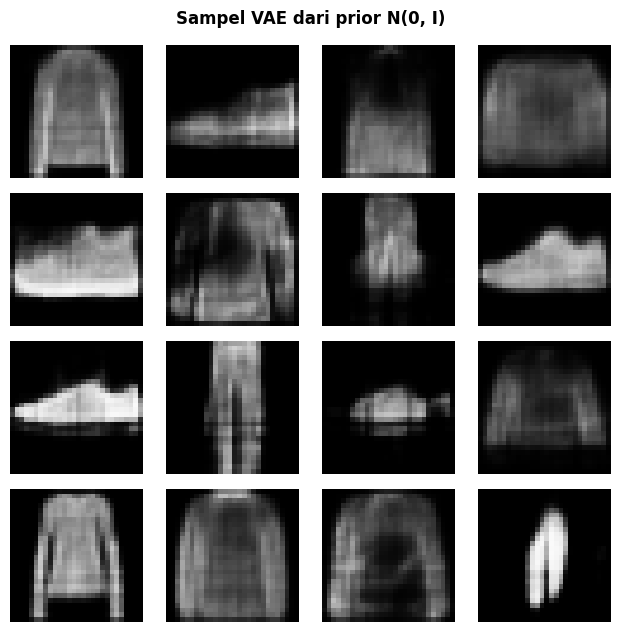

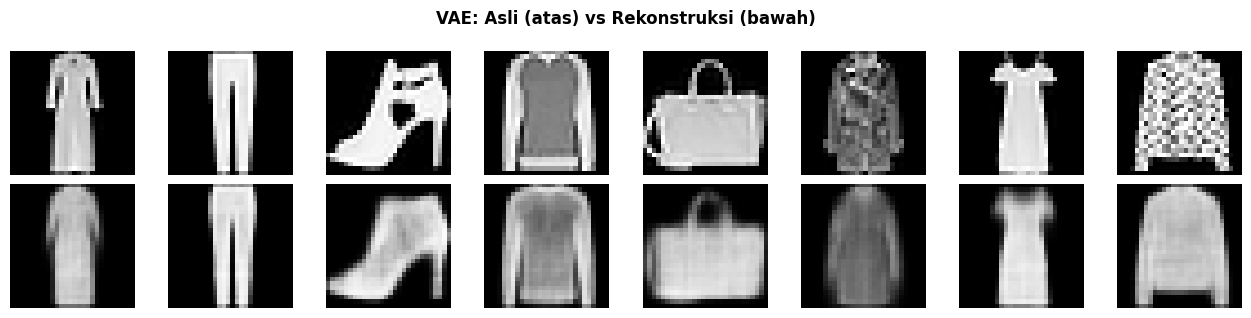

In [15]:
vae.eval()
vae_mse, vae_psnr, vae_ssim = evaluate_reconstruction(lambda x: vae.decode(vae.encode(x)[0]), test_loader)

set_seed(SEED)
with torch.no_grad():
    vae_fake = vae.decode(torch.randn(FID_N_SAMPLES, vae.latent_dim, device=device)).cpu()
vae_fid = compute_fid_from_features(real_fid_features, extract_inception_features(vae_fake, inception_model))

vae_latency = measure_latency_ms(lambda: vae.decode(torch.randn(64, vae.latent_dim, device=device)), repeats=100)

vae_result = {
    "model": "VAE",
    "latent_dim": 64,
    "train_time_per_epoch_s": round(vae_history["epoch_time_s"].mean(), 3),
    "latency_ms": vae_latency,
    "mse": vae_mse,
    "psnr": vae_psnr,
    "ssim": vae_ssim,
    "fid": vae_fid,
}
print(vae_result)

set_seed(SEED)
with torch.no_grad():
    vae_samples = vae.decode(torch.randn(16, vae.latent_dim, device=device))
    x8_vae = vae.decode(vae.encode(x8)[0])
save_grid(vae_samples, 4, 4, "Sampel VAE dari prior N(0, I)", os.path.join(FIGS_DIR, "vae_samples_preview.png"))
save_grid(torch.cat([x8, x8_vae]), 2, 8, "VAE: Asli (atas) vs Rekonstruksi (bawah)", os.path.join(FIGS_DIR, "vae_recon_preview.png"))


## 8. Vanilla GAN


In [16]:
class GANGenerator(nn.Module):
    def __init__(self, latent_dim=64, out_dim=784):
        super().__init__()
        self.latent_dim = latent_dim
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, out_dim),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class GANDiscriminator(nn.Module):
    def __init__(self, in_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.net(x.flatten(1))

def to_signed(x):
    return x * 2 - 1

def to_unit(x):
    return ((x + 1) / 2).clamp(0.0, 1.0)

@torch.no_grad()
def sample_generator(generator, n, chunk=500):
    generator.eval()
    out = []
    for i in range(0, n, chunk):
        z = torch.randn(min(chunk, n - i), generator.latent_dim, device=device)
        out.append(to_unit(generator(z)).cpu())
    return torch.cat(out)

def train_gan(generator, discriminator, epochs, lr):
    criterion = nn.BCEWithLogitsLoss()
    opt_g = torch.optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))
    rows = []
    for epoch in range(1, epochs + 1):
        generator.train()
        discriminator.train()
        start = time.perf_counter()
        totals = {"d_loss": 0.0, "g_loss": 0.0, "d_real": 0.0, "d_fake": 0.0}
        for x, _ in train_loader:
            real = to_signed(x.to(device))
            n = real.size(0)
            ones = torch.ones(n, 1, device=device)
            zeros = torch.zeros(n, 1, device=device)
            fake = generator(torch.randn(n, generator.latent_dim, device=device))

            opt_d.zero_grad()
            real_logits = discriminator(real)
            fake_logits = discriminator(fake.detach())
            d_loss = criterion(real_logits, ones) + criterion(fake_logits, zeros)
            d_loss.backward()
            opt_d.step()

            opt_g.zero_grad()
            g_loss = criterion(discriminator(fake), ones)
            g_loss.backward()
            opt_g.step()

            totals["d_loss"] += d_loss.item() * n
            totals["g_loss"] += g_loss.item() * n
            totals["d_real"] += torch.sigmoid(real_logits).mean().item() * n
            totals["d_fake"] += torch.sigmoid(fake_logits).mean().item() * n
        epoch_time = time.perf_counter() - start
        row = {"epoch": epoch, **{k: v / len(train_ds) for k, v in totals.items()}, "epoch_time_s": epoch_time}
        rows.append(row)
        print(f"Epoch {epoch:02d}/{epochs} | D {row['d_loss']:.4f} | G {row['g_loss']:.4f} | D(x) {row['d_real']:.3f} | D(G(z)) {row['d_fake']:.3f} | {epoch_time:.2f}s")
    return pd.DataFrame(rows)

for name, module in (("Generator", GANGenerator()), ("Discriminator", GANDiscriminator())):
    print(module)
    trainable, total = count_parameters(module)
    print(f"{name} params trainable: {trainable:,} | total: {total:,}")
print(GANGenerator()(torch.randn(2, 64)).shape, GANDiscriminator()(torch.randn(2, 1, 28, 28)).shape)


GANGenerator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Generator params trainable: 1,477,136 | total: 1,477,136
GANDiscriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)
Discriminator params trainable: 533,505 | total: 533,505
torch.Size([2, 1, 28, 28]) torch.Size([2, 1])


### 8.1 Training Vanilla GAN

In [17]:
GAN_LATENT = 64
GAN_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "vanilla_gan.pt")
GAN_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_vanilla_gan.csv")
GAN_EPOCHS = 30
GAN_LR = 2e-4

set_seed(SEED)
loader_gen.manual_seed(SEED)
gan_g = GANGenerator(GAN_LATENT).to(device)
gan_d = GANDiscriminator().to(device)

if os.path.exists(GAN_WEIGHTS_PATH) and os.path.exists(GAN_HISTORY_PATH) and not FORCE_RERUN:
    checkpoint = torch.load(GAN_WEIGHTS_PATH, map_location=device, weights_only=True)
    gan_g.load_state_dict(checkpoint["generator"])
    gan_d.load_state_dict(checkpoint["discriminator"])
    gan_history = pd.read_csv(GAN_HISTORY_PATH)
    print("Cache dimuat: vanilla_gan.pt")
else:
    gan_history = train_gan(gan_g, gan_d, GAN_EPOCHS, GAN_LR)
    torch.save({"generator": gan_g.state_dict(), "discriminator": gan_d.state_dict()}, GAN_WEIGHTS_PATH)
    gan_history.to_csv(GAN_HISTORY_PATH, index=False)

display(gan_history.tail())

Cache dimuat: vanilla_gan.pt


,epoch,d_loss,g_loss,d_real,d_fake,epoch_time_s
25,26,1.301901,0.926064,0.539761,0.461118,1.543972
26,27,1.301775,0.933184,0.539743,0.460987,1.642631
27,28,1.304391,0.926044,0.538613,0.462266,1.700409
28,29,1.305046,0.910549,0.537112,0.463086,1.587467
29,30,1.309214,0.907845,0.535704,0.464298,1.599732


### 8.2 Evaluasi Vanilla GAN

Mean piksel sampel: 0.276 | asli: 0.285
{'model': 'Vanilla GAN', 'latent_dim': 64, 'train_time_per_epoch_s': 1.648, 'latency_ms': 0.209, 'mse': None, 'psnr': None, 'ssim': None, 'fid': 152.44797372962347}
      d_loss  g_loss  d_real  d_fake
mean  1.2970  0.9444  0.5420  0.4590
std   0.0092  0.0287  0.0046  0.0041


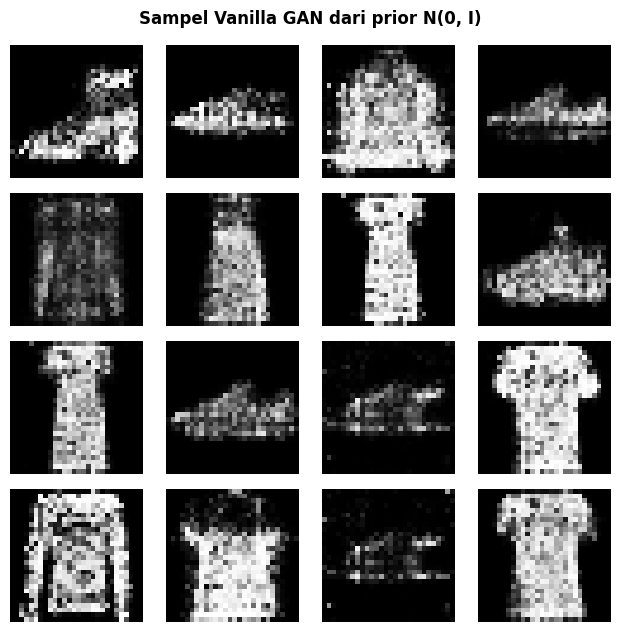

In [18]:
gan_g.eval()

set_seed(SEED)
gan_fake = sample_generator(gan_g, FID_N_SAMPLES)
gan_fid = compute_fid_from_features(real_fid_features, extract_inception_features(gan_fake, inception_model))
print(f"Mean piksel sampel: {gan_fake.mean().item():.3f} | asli: {real_fid_images.mean().item():.3f}")

gan_latency = measure_latency_ms(lambda: to_unit(gan_g(torch.randn(64, GAN_LATENT, device=device))), repeats=100)

gan_result = {
    "model": "Vanilla GAN",
    "latent_dim": GAN_LATENT,
    "train_time_per_epoch_s": round(gan_history["epoch_time_s"].mean(), 3),
    "latency_ms": gan_latency,
    "mse": None,
    "psnr": None,
    "ssim": None,
    "fid": gan_fid,
}
print(gan_result)
print(gan_history[["d_loss", "g_loss", "d_real", "d_fake"]].tail(10).agg(["mean", "std"]).round(4))

save_grid(gan_fake[:16], 4, 4, "Sampel Vanilla GAN dari prior N(0, I)", os.path.join(FIGS_DIR, "vanilla_gan_samples_preview.png"))

## 9. DCGAN

In [19]:
class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.latent_dim = latent_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 7, 1, 0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 1, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z.view(-1, self.latent_dim, 1, 1))

class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 1, 7, 1, 0, bias=False),
        )

    def forward(self, x):
        return self.net(x).view(-1, 1)

def init_dcgan_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

for name, module in (("Generator", DCGANGenerator()), ("Discriminator", DCGANDiscriminator())):
    print(module)
    trainable, total = count_parameters(module)
    print(f"{name} params trainable: {trainable:,} | total: {total:,}")
print(DCGANGenerator()(torch.randn(2, 100)).shape, DCGANDiscriminator()(torch.randn(2, 1, 28, 28)).shape)

DCGANGenerator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)
Generator params trainable: 1,781,504 | total: 1,781,504
DCGANDiscriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Conv

### 9.1 Training DCGAN

In [20]:
DCGAN_LATENT = 100
DCGAN_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "dcgan.pt")
DCGAN_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_dcgan.csv")
DCGAN_EPOCHS = 30
DCGAN_LR = 2e-4

set_seed(SEED)
loader_gen.manual_seed(SEED)
dcgan_g = DCGANGenerator(DCGAN_LATENT).to(device)
dcgan_d = DCGANDiscriminator().to(device)
dcgan_g.apply(init_dcgan_weights)
dcgan_d.apply(init_dcgan_weights)

if os.path.exists(DCGAN_WEIGHTS_PATH) and os.path.exists(DCGAN_HISTORY_PATH) and not FORCE_RERUN:
    checkpoint = torch.load(DCGAN_WEIGHTS_PATH, map_location=device, weights_only=True)
    dcgan_g.load_state_dict(checkpoint["generator"])
    dcgan_d.load_state_dict(checkpoint["discriminator"])
    dcgan_history = pd.read_csv(DCGAN_HISTORY_PATH)
    print("Cache dimuat: dcgan.pt")
else:
    dcgan_history = train_gan(dcgan_g, dcgan_d, DCGAN_EPOCHS, DCGAN_LR)
    torch.save({"generator": dcgan_g.state_dict(), "discriminator": dcgan_d.state_dict()}, DCGAN_WEIGHTS_PATH)
    dcgan_history.to_csv(DCGAN_HISTORY_PATH, index=False)

display(dcgan_history.tail())

Cache dimuat: dcgan.pt


,epoch,d_loss,g_loss,d_real,d_fake,epoch_time_s
25,26,1.190318,1.081852,0.582826,0.417442,4.671061
26,27,1.185601,1.076986,0.582670,0.417190,4.705564
27,28,1.186446,1.071973,0.582148,0.418065,4.695187
28,29,1.202767,1.078553,0.580403,0.419602,4.670682
29,30,1.190602,1.076756,0.581786,0.418334,4.694220


### 9.2 Evaluasi DCGAN

Mean piksel sampel: 0.293 | asli: 0.285
{'model': 'DCGAN', 'latent_dim': 100, 'train_time_per_epoch_s': 4.701, 'latency_ms': 1.32, 'mse': None, 'psnr': None, 'ssim': None, 'fid': 25.543650585711987}
      d_loss  g_loss  d_real  d_fake
mean  1.1878  1.0838  0.5831  0.4170
std   0.0068  0.0092  0.0016  0.0016


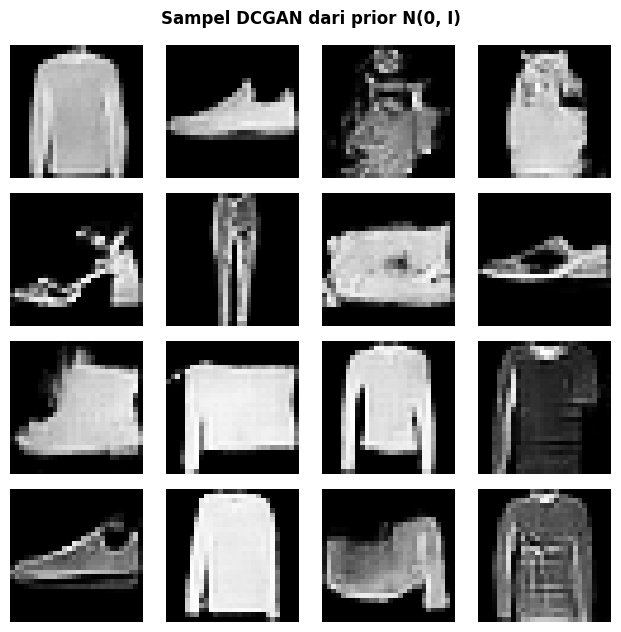

In [21]:
dcgan_g.eval()

set_seed(SEED)
dcgan_fake = sample_generator(dcgan_g, FID_N_SAMPLES)
dcgan_fid = compute_fid_from_features(real_fid_features, extract_inception_features(dcgan_fake, inception_model))
print(f"Mean piksel sampel: {dcgan_fake.mean().item():.3f} | asli: {real_fid_images.mean().item():.3f}")

dcgan_latency = measure_latency_ms(lambda: to_unit(dcgan_g(torch.randn(64, DCGAN_LATENT, device=device))), repeats=100)

dcgan_result = {
    "model": "DCGAN",
    "latent_dim": DCGAN_LATENT,
    "train_time_per_epoch_s": round(dcgan_history["epoch_time_s"].mean(), 3),
    "latency_ms": dcgan_latency,
    "mse": None,
    "psnr": None,
    "ssim": None,
    "fid": dcgan_fid,
}
print(dcgan_result)
print(dcgan_history[["d_loss", "g_loss", "d_real", "d_fake"]].tail(10).agg(["mean", "std"]).round(4))

save_grid(dcgan_fake[:16], 4, 4, "Sampel DCGAN dari prior N(0, I)", os.path.join(FIGS_DIR, "dcgan_samples_preview.png"))

## 10. Denoising Diffusion Probabilistic Model (DDPM)

In [22]:
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(torch.arange(half, device=t.device) * (-float(np.log(10000.0)) / half))
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class DDPMUNet(nn.Module):
    def __init__(self, base=64, time_dim=256):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalEmbedding(base),
            nn.Linear(base, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.conv_in = nn.Conv2d(1, base, 3, padding=1)
        self.down1 = ResBlock(base, base, time_dim)
        self.pool1 = nn.Conv2d(base, base, 3, stride=2, padding=1)
        self.down2 = ResBlock(base, base * 2, time_dim)
        self.pool2 = nn.Conv2d(base * 2, base * 2, 3, stride=2, padding=1)
        self.mid1 = ResBlock(base * 2, base * 2, time_dim)
        self.mid2 = ResBlock(base * 2, base * 2, time_dim)
        self.up2 = nn.ConvTranspose2d(base * 2, base * 2, 4, stride=2, padding=1)
        self.up_block2 = ResBlock(base * 4, base * 2, time_dim)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 4, stride=2, padding=1)
        self.up_block1 = ResBlock(base * 2, base, time_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1))

    def forward(self, x, t):
        emb = self.time_mlp(t)
        s1 = self.down1(self.conv_in(x), emb)
        s2 = self.down2(self.pool1(s1), emb)
        h = self.mid2(self.mid1(self.pool2(s2), emb), emb)
        h = self.up_block2(torch.cat([self.up2(h), s2], dim=1), emb)
        h = self.up_block1(torch.cat([self.up1(h), s1], dim=1), emb)
        return self.out(h)

DDPM_T = 300
betas = torch.linspace(1e-4, 0.02 * 1000 / DDPM_T, DDPM_T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alphas = alphas.sqrt()
sqrt_ab = alpha_bars.sqrt()
sqrt_one_minus_ab = (1.0 - alpha_bars).sqrt()
eps_coef = betas / sqrt_one_minus_ab
sigmas = betas.sqrt()

def q_sample(x0, t, noise):
    return sqrt_ab[t].view(-1, 1, 1, 1) * x0 + sqrt_one_minus_ab[t].view(-1, 1, 1, 1) * noise

@torch.no_grad()
def evaluate_ddpm_loss(model, loader):
    model.eval()
    gen = torch.Generator(device=device).manual_seed(SEED)
    total, count = 0.0, 0
    for x, _ in loader:
        x0 = to_signed(x.to(device))
        t = torch.randint(0, DDPM_T, (x0.size(0),), device=device, generator=gen)
        noise = torch.randn(x0.shape, device=device, generator=gen)
        total += F.mse_loss(model(q_sample(x0, t, noise), t), noise, reduction="sum").item()
        count += x0.numel()
    return total / count

@torch.no_grad()
def ddpm_sample(model, n, trace_steps=()):
    model.eval()
    x = torch.randn(n, 1, 28, 28, device=device)
    trace = [(DDPM_T, to_unit(x).cpu())] if trace_steps else []
    for t in reversed(range(DDPM_T)):
        t_batch = torch.full((n,), t, device=device, dtype=torch.long)
        x = (x - eps_coef[t] * model(x, t_batch)) / sqrt_alphas[t]
        if t > 0:
            x = x + sigmas[t] * torch.randn_like(x)
        if t in trace_steps:
            trace.append((t, to_unit(x).cpu()))
    return to_unit(x), trace

def sample_ddpm(model, n, chunk=500):
    out = []
    for i in range(0, n, chunk):
        images, _ = ddpm_sample(model, min(chunk, n - i))
        out.append(images.cpu())
    return torch.cat(out)

print(f"beta_end: {betas[-1].item():.4f} | alpha_bar_T: {alpha_bars[-1].item():.2e}")
assert alpha_bars[-1].item() < 1e-3

probe = DDPMUNet()
trainable, total = count_parameters(probe)
print(f"U-Net params trainable: {trainable:,} | total: {total:,}")
print(probe(torch.randn(2, 1, 28, 28), torch.tensor([0, DDPM_T - 1])).shape)

beta_end: 0.0667 | alpha_bar_T: 3.55e-05
U-Net params trainable: 2,317,441 | total: 2,317,441
torch.Size([2, 1, 28, 28])


### 10.1 Training DDPM

In [23]:
DDPM_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "ddpm.pt")
DDPM_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_ddpm.csv")
DDPM_EPOCHS = 40
DDPM_LR = 2e-4
DDPM_EMA_DECAY = 0.999

set_seed(SEED)
loader_gen.manual_seed(SEED)
unet = DDPMUNet().to(device)
ema_unet = DDPMUNet().to(device)
ema_unet.load_state_dict(unet.state_dict())

if os.path.exists(DDPM_WEIGHTS_PATH) and os.path.exists(DDPM_HISTORY_PATH) and not FORCE_RERUN:
    ema_unet.load_state_dict(torch.load(DDPM_WEIGHTS_PATH, map_location=device, weights_only=True))
    ddpm_history = pd.read_csv(DDPM_HISTORY_PATH)
    print("Cache dimuat: ddpm.pt")
else:
    optimizer = torch.optim.Adam(unet.parameters(), lr=DDPM_LR)
    rows = []
    for epoch in range(1, DDPM_EPOCHS + 1):
        unet.train()
        start = time.perf_counter()
        running_loss = 0.0
        for x, _ in train_loader:
            x0 = to_signed(x.to(device))
            n = x0.size(0)
            t = torch.randint(0, DDPM_T, (n,), device=device)
            noise = torch.randn_like(x0)
            optimizer.zero_grad()
            loss = F.mse_loss(unet(q_sample(x0, t, noise), t), noise)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
            optimizer.step()
            with torch.no_grad():
                for p_ema, p in zip(ema_unet.parameters(), unet.parameters()):
                    p_ema.mul_(DDPM_EMA_DECAY).add_(p, alpha=1 - DDPM_EMA_DECAY)
            running_loss += loss.item() * n
        epoch_time = time.perf_counter() - start
        train_loss = running_loss / len(train_ds)
        val_loss = evaluate_ddpm_loss(ema_unet, val_loader)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "epoch_time_s": epoch_time})
        print(f"Epoch {epoch:02d}/{DDPM_EPOCHS} | train {train_loss:.5f} | val (EMA) {val_loss:.5f} | {epoch_time:.2f}s")
    torch.save(ema_unet.state_dict(), DDPM_WEIGHTS_PATH)
    ddpm_history = pd.DataFrame(rows)
    ddpm_history.to_csv(DDPM_HISTORY_PATH, index=False)

display(ddpm_history.tail())

Cache dimuat: ddpm.pt


,epoch,train_loss,val_loss,epoch_time_s
35,36,0.037271,0.036704,25.103937
36,37,0.037485,0.036663,25.147024
37,38,0.037291,0.036607,25.187385
38,39,0.037189,0.036557,25.317078
39,40,0.036888,0.036511,25.306063


### 10.2 Evaluasi DDPM

Cache dimuat: ddpm_samples.pt


Sampel: (5000, 1, 28, 28) | mean piksel sampel: 0.287 | asli: 0.285


{'model': 'DDPM', 'latent_dim': '28x28', 'train_time_per_epoch_s': 25.175, 'latency_ms': 2320.521, 'mse': None, 'psnr': None, 'ssim': None, 'fid': 14.879000512052926}
      train_loss  val_loss
mean     0.03753   0.03674
std      0.00044   0.00016


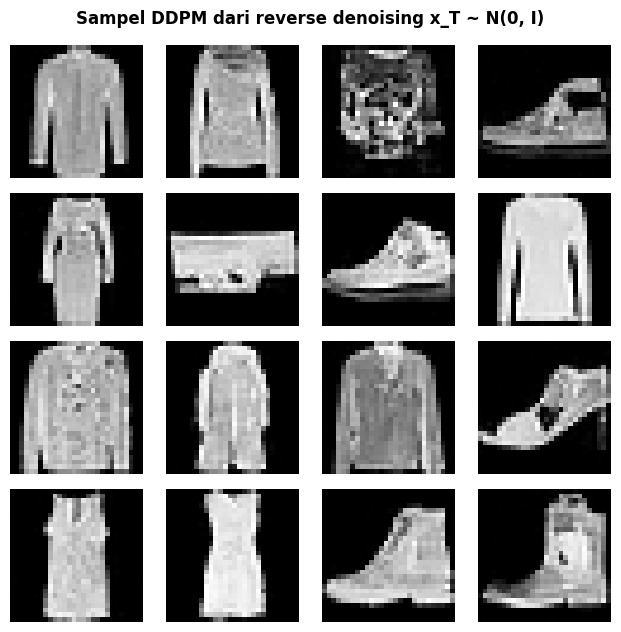

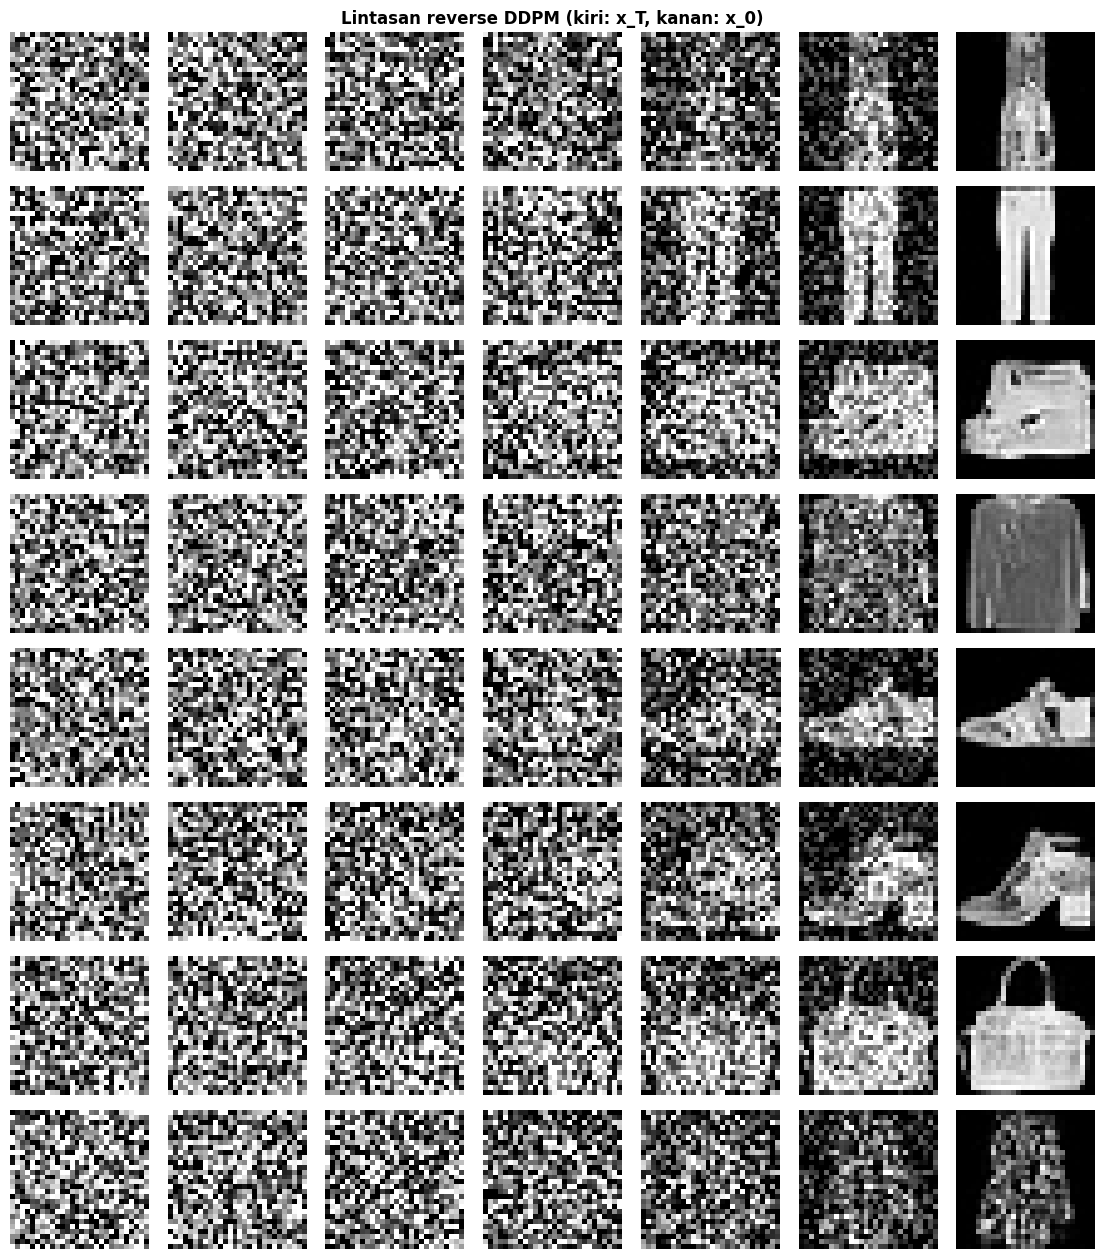

In [24]:
DDPM_SAMPLES_PATH = os.path.join(WEIGHTS_DIR, "ddpm_samples.pt")
DDPM_TRACE_STEPS = (250, 200, 150, 100, 50, 0)

set_seed(SEED)
if os.path.exists(DDPM_SAMPLES_PATH) and not FORCE_RERUN:
    ddpm_fake = torch.load(DDPM_SAMPLES_PATH, weights_only=True)
    print("Cache dimuat: ddpm_samples.pt")
else:
    ddpm_fake = sample_ddpm(ema_unet, FID_N_SAMPLES)
    torch.save(ddpm_fake, DDPM_SAMPLES_PATH)

ddpm_fid = compute_fid_from_features(real_fid_features, extract_inception_features(ddpm_fake, inception_model))
print(f"Sampel: {tuple(ddpm_fake.shape)} | mean piksel sampel: {ddpm_fake.mean().item():.3f} | asli: {real_fid_images.mean().item():.3f}")

ddpm_latency = measure_latency_ms(lambda: ddpm_sample(ema_unet, 64), warmup=1, repeats=3)

ddpm_result = {
    "model": "DDPM",
    "latent_dim": "28x28",
    "train_time_per_epoch_s": round(ddpm_history["epoch_time_s"].mean(), 3),
    "latency_ms": ddpm_latency,
    "mse": None,
    "psnr": None,
    "ssim": None,
    "fid": ddpm_fid,
}
print(ddpm_result)
print(ddpm_history[["train_loss", "val_loss"]].tail(10).agg(["mean", "std"]).round(5))

save_grid(ddpm_fake[:16], 4, 4, "Sampel DDPM dari reverse denoising x_T ~ N(0, I)", os.path.join(FIGS_DIR, "ddpm_samples_preview.png"))

set_seed(SEED)
_, ddpm_trace = ddpm_sample(ema_unet, 8, DDPM_TRACE_STEPS)
trace_grid = torch.cat([img[i : i + 1] for i in range(8) for _, img in ddpm_trace])
save_grid(trace_grid, 8, len(ddpm_trace), "Lintasan reverse DDPM (kiri: x_T, kanan: x_0)", os.path.join(FIGS_DIR, "ddpm_trace_preview.png"))

## 11. Tabel Benchmark Komparatif

In [25]:
results = [ae_result, sparse_result, vae_result, gan_result, dcgan_result, ddpm_result]
histories = {
    "Vanilla AE": ae_history,
    "Sparse AE": sparse_history,
    "VAE": vae_history,
    "Vanilla GAN": gan_history,
    "DCGAN": dcgan_history,
    "DDPM": ddpm_history,
}

runs_df = pd.DataFrame(results)
assert len(runs_df) == 6
runs_df.to_csv(RUNS_PATH, index=False)

table_columns = ["model", "latent_dim", "train_time_per_epoch_s", "latency_ms", "mse", "psnr", "ssim", "fid"]
display(runs_df[table_columns].round(4).astype(object).fillna("N/A"))

stability = {}
for name, history in histories.items():
    tail = history.drop(columns=["epoch", "epoch_time_s"]).tail(10)
    stability[name] = {col: {"mean": float(tail[col].mean()), "std": float(tail[col].std())} for col in tail.columns}

stability_df = pd.DataFrame({name: {col: f"{s['mean']:.4f} ± {s['std']:.4f}" for col, s in cols.items()} for name, cols in stability.items()})
display(stability_df.fillna("N/A"))

metrics = {
    "seed": SEED,
    "split": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)},
    "fid_n_samples": FID_N_SAMPLES,
    "mlp_classifier": {"test_acc": mlp_test_acc, "test_loss": mlp_test_loss},
    "models": {r["model"]: {k: v for k, v in r.items() if k != "model"} for r in results},
    "stability_last10_epochs": stability,
}
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"Tersimpan: {RUNS_PATH} | {METRICS_PATH}")

,model,latent_dim,train_time_per_epoch_s,latency_ms,mse,psnr,ssim,fid
0,Vanilla AE,64,1.247,0.117,0.0064,23.0695,0.792,N/A
1,Sparse AE,256,1.346,0.133,0.0069,22.6602,0.7777,N/A
2,VAE,64,1.595,0.138,0.013,19.6964,0.6536,88.0002
3,Vanilla GAN,64,1.648,0.209,N/A,N/A,N/A,152.448
4,DCGAN,100,4.701,1.320,N/A,N/A,N/A,25.5437
5,DDPM,28x28,25.175,2320.521,N/A,N/A,N/A,14.879


,Vanilla AE,Sparse AE,VAE,Vanilla GAN,DCGAN,DDPM
train_loss,0.0065 ± 0.0002,0.0078 ± 0.0002,241.2896 ± 0.3109,N/A,N/A,0.0375 ± 0.0004
val_loss,0.0067 ± 0.0002,0.0081 ± 0.0002,242.1581 ± 0.2522,N/A,N/A,0.0367 ± 0.0002
train_recon,N/A,0.0070 ± 0.0002,225.3640 ± 0.2878,N/A,N/A,N/A
val_recon,N/A,0.0073 ± 0.0002,N/A,N/A,N/A,N/A
train_kl,N/A,N/A,15.9256 ± 0.0269,N/A,N/A,N/A
d_loss,N/A,N/A,N/A,1.2970 ± 0.0092,1.1878 ± 0.0068,N/A
g_loss,N/A,N/A,N/A,0.9444 ± 0.0287,1.0838 ± 0.0092,N/A
d_real,N/A,N/A,N/A,0.5420 ± 0.0046,0.5831 ± 0.0016,N/A
d_fake,N/A,N/A,N/A,0.4590 ± 0.0041,0.4170 ± 0.0016,N/A


Tersimpan: results/runs.csv | results/metrics.json


## 12. Pembuktian Batasan MLP Classifier

In [26]:
W1 = mlp.fc1.weight.detach()
W2 = mlp.fc2.weight.detach()
W3 = mlp.fc3.weight.detach()

def backproject_class(y_onehot):
    z_hat = F.relu(y_onehot @ W3)
    h1_hat = F.relu(z_hat @ W2)
    return torch.sigmoid(h1_hat @ W1).view(-1, 1, 28, 28)

def backproject_latent(z):
    return torch.sigmoid(F.relu(z @ W2) @ W1).view(-1, 1, 28, 28)

def row_offdiag_ratio(W):
    gram = W @ W.T
    off = gram - torch.diag(torch.diag(gram))
    return (off.norm() / gram.norm()).item()

offdiag_ratio = {"W1": row_offdiag_ratio(W1), "W2": row_offdiag_ratio(W2), "W3": row_offdiag_ratio(W3)}
stage2_images = backproject_class(torch.eye(10, device=device))

print(f"W1 {tuple(W1.shape)} | W2 {tuple(W2.shape)} | W3 {tuple(W3.shape)}")
print("Rasio off-diagonal W W^T (0 = baris ortogonal): " + " | ".join(f"{k} {v:.3f}" for k, v in offdiag_ratio.items()))
print(f"Stage 2: {tuple(stage2_images.shape)} | rentang {stage2_images.min().item():.3f} sampai {stage2_images.max().item():.3f}")

W1 (256, 784) | W2 (64, 256) | W3 (10, 64)
Rasio off-diagonal W W^T (0 = baris ortogonal): W1 0.920 | W2 0.866 | W3 0.465
Stage 2: (10, 1, 28, 28) | rentang 0.078 sampai 0.886


### 12.1 Stage 4: Frozen Latent Decoder

In [27]:
class LatentDecoder(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=256, out_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, out_dim),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

@torch.no_grad()
def evaluate_frozen_mse(decoder, loader):
    decoder.eval()
    total, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        total += F.mse_loss(decoder(mlp.encode(x)), x, reduction="sum").item()
        count += x.numel()
    return total / count

FROZEN_WEIGHTS_PATH = os.path.join(WEIGHTS_DIR, "frozen_decoder.pt")
FROZEN_HISTORY_PATH = os.path.join(RESULTS_DIR, "history_frozen_decoder.csv")

for p in mlp.parameters():
    p.requires_grad_(False)
mlp.eval()
assert not any(p.requires_grad for p in mlp.parameters())
mlp_trainable, mlp_total = count_parameters(mlp)
print(f"MLP trainable: {mlp_trainable:,} | total: {mlp_total:,}")
print(f"Decoder params: {count_parameters(LatentDecoder())[1]:,}")

set_seed(SEED)
loader_gen.manual_seed(SEED)
frozen_decoder = LatentDecoder().to(device)

if os.path.exists(FROZEN_WEIGHTS_PATH) and os.path.exists(FROZEN_HISTORY_PATH) and not FORCE_RERUN:
    frozen_decoder.load_state_dict(torch.load(FROZEN_WEIGHTS_PATH, map_location=device, weights_only=True))
    frozen_history = pd.read_csv(FROZEN_HISTORY_PATH)
    print("Cache dimuat: frozen_decoder.pt")
else:
    optimizer = torch.optim.Adam(frozen_decoder.parameters(), lr=AE_LR)
    best_loss, best_state, rows = float("inf"), None, []
    for epoch in range(1, AE_EPOCHS + 1):
        frozen_decoder.train()
        start = time.perf_counter()
        running_loss = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            with torch.no_grad():
                z = mlp.encode(x)
            optimizer.zero_grad()
            loss = F.mse_loss(frozen_decoder(z), x)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
        epoch_time = time.perf_counter() - start
        train_loss = running_loss / len(train_ds)
        val_loss = evaluate_frozen_mse(frozen_decoder, val_loader)
        rows.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "epoch_time_s": epoch_time})
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in frozen_decoder.state_dict().items()}
        print(f"Epoch {epoch:02d}/{AE_EPOCHS} | train {train_loss:.5f} | val {val_loss:.5f} | {epoch_time:.2f}s")
    frozen_decoder.load_state_dict(best_state)
    torch.save(frozen_decoder.state_dict(), FROZEN_WEIGHTS_PATH)
    frozen_history = pd.DataFrame(rows)
    frozen_history.to_csv(FROZEN_HISTORY_PATH, index=False)

display(frozen_history.tail())

MLP trainable: 0 | total: 218,058
Decoder params: 218,128
Cache dimuat: frozen_decoder.pt


,epoch,train_loss,val_loss,epoch_time_s
25,26,0.016448,0.016828,0.687717
26,27,0.016409,0.016717,0.720174
27,28,0.016380,0.016765,0.726692
28,29,0.016312,0.016732,0.759515
29,30,0.016291,0.016654,0.751725


### 12.2 Evaluasi Stage 3 sampai 5 dan Figur 3

,metode,mse,psnr_db,ssim
0,Transpos W^T dari z_MLP (Stage 3),0.2685,5.7642,0.0825
1,Frozen Latent Decoder (Stage 4),0.0166,18.5891,0.6002
2,Vanilla AE (referensi),0.0064,23.0695,0.7920


FID prior sampling MLP: 135.01 | FID prior sampling VAE: 88.00
Fraksi z_rand < 0: 0.148 | z_MLP < 0: 0.000


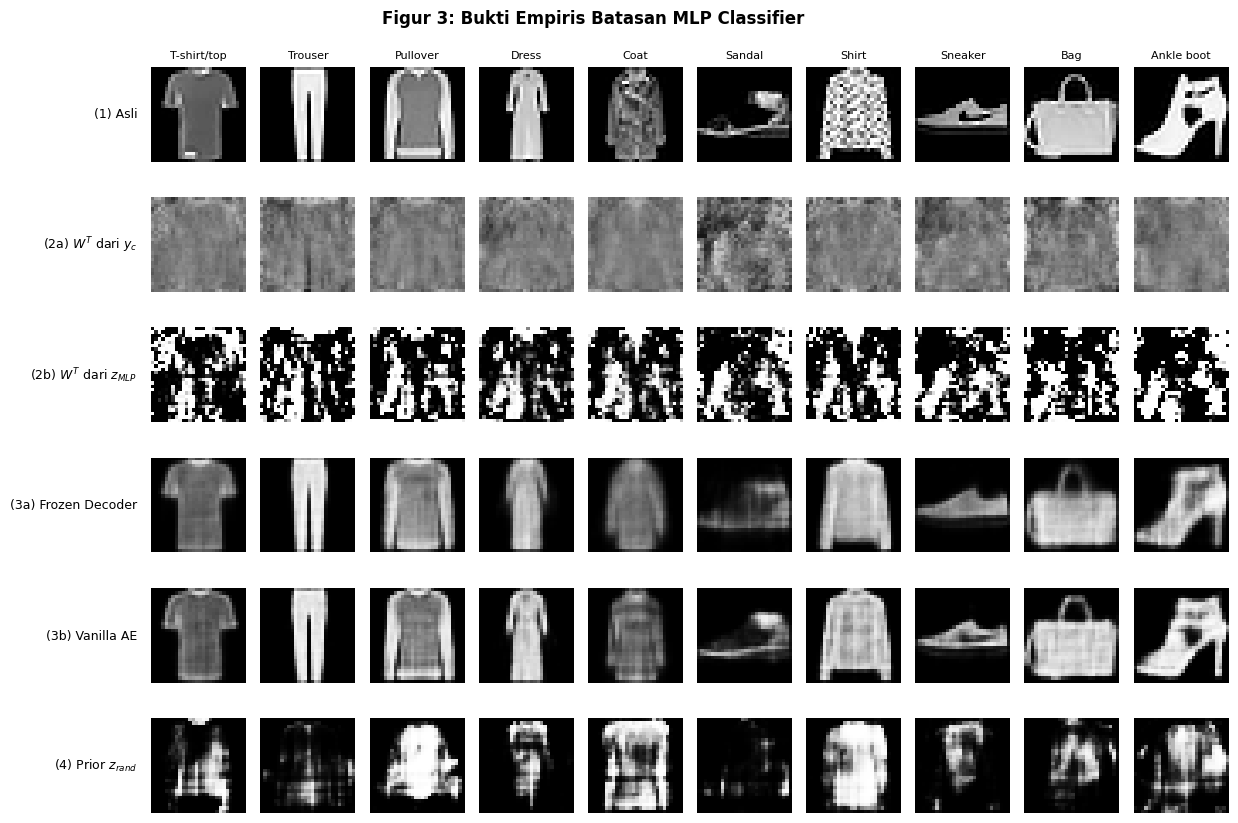

In [28]:
frozen_decoder.eval()
ae.eval()

stage3_mse, stage3_psnr, stage3_ssim = evaluate_reconstruction(lambda x: backproject_latent(mlp.encode(x)), test_loader)
frozen_mse, frozen_psnr, frozen_ssim = evaluate_reconstruction(lambda x: frozen_decoder(mlp.encode(x)), test_loader)

proof_df = pd.DataFrame(
    [
        ("Transpos W^T dari z_MLP (Stage 3)", stage3_mse, stage3_psnr, stage3_ssim),
        ("Frozen Latent Decoder (Stage 4)", frozen_mse, frozen_psnr, frozen_ssim),
        ("Vanilla AE (referensi)", ae_mse, ae_psnr, ae_ssim),
    ],
    columns=["metode", "mse", "psnr_db", "ssim"],
)
display(proof_df.round(4))

with torch.no_grad():
    z_test_mlp = torch.cat([mlp.encode(x.to(device)).cpu() for x, _ in test_loader])

set_seed(SEED)
mu_z = z_test_mlp.mean(dim=0)
sigma_z = z_test_mlp.std(dim=0)
z_prior = mu_z + sigma_z * torch.randn(FID_N_SAMPLES, mu_z.numel())
with torch.no_grad():
    prior_images = frozen_decoder(z_prior.to(device)).cpu()

mlp_prior_fid = compute_fid_from_features(real_fid_features, extract_inception_features(prior_images, inception_model))
negative_fraction = (z_prior < 0).float().mean().item()
print(f"FID prior sampling MLP: {mlp_prior_fid:.2f} | FID prior sampling VAE: {vae_fid:.2f}")
print(f"Fraksi z_rand < 0: {negative_fraction:.3f} | z_MLP < 0: {(z_test_mlp < 0).float().mean().item():.3f}")

class_idx = [(test_ds.tensors[1] == c).nonzero(as_tuple=True)[0][0].item() for c in range(10)]
x_class = test_ds.tensors[0][class_idx].to(device)

with torch.no_grad():
    z_class = mlp.encode(x_class)
    figure_rows = [
        ("(1) Asli", x_class),
        ("(2a) $W^T$ dari $y_c$", stage2_images),
        ("(2b) $W^T$ dari $z_{MLP}$", backproject_latent(z_class)),
        ("(3a) Frozen Decoder", frozen_decoder(z_class)),
        ("(3b) Vanilla AE", ae(x_class)),
        ("(4) Prior $z_{rand}$", prior_images[:10]),
    ]

fig, axes = plt.subplots(len(figure_rows), 10, figsize=(13, 8.5))
for r, (label, imgs) in enumerate(figure_rows):
    for c in range(10):
        axes[r, c].imshow(imgs[c, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
    axes[r, 0].text(-0.15, 0.5, label, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
for c in range(10):
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=8)
plt.suptitle("Figur 3: Bukti Empiris Batasan MLP Classifier", fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(left=0.16)
plt.savefig(os.path.join(FIGS_DIR, "fig3_mlp_limitation.png"), dpi=300, bbox_inches="tight")
plt.show()

mlp_proof = {
    "weight_row_offdiag_ratio": offdiag_ratio,
    "stage3_transpose_from_z": {"mse": stage3_mse, "psnr": stage3_psnr, "ssim": stage3_ssim},
    "stage4_frozen_decoder": {"mse": frozen_mse, "psnr": frozen_psnr, "ssim": frozen_ssim},
    "vanilla_ae_reference": {"mse": ae_mse, "psnr": ae_psnr, "ssim": ae_ssim},
    "stage5_prior_sampling": {"fid": mlp_prior_fid, "negative_fraction": negative_fraction},
}
with open(METRICS_PATH) as f:
    metrics = json.load(f)
metrics["mlp_proof"] = mlp_proof
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)